In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pylab as plt
%matplotlib inline

In [2]:
words =open("names.txt", "r").read().splitlines()

In [3]:
chars = sorted(set("".join(words)))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi["."] = 0
itos = {i:s for s, i in stoi.items()}
context_size = 4

In [4]:
def build_dataset(words):
  xs = []
  ys = []
  # n-gram
  for word in words:
    # print(word)
    context = [0] * context_size
    for ch in word + ".":
      idx = stoi[ch]
      ys.append(idx)
      xs.append(context)
      # print(f"{"".join(itos[i] for i in block)} ---> {itos[idx]}")
      context = context[1:] + [idx]

  xs = torch.tensor(xs)
  ys = torch.tensor(ys)
  return xs, ys

In [5]:
import random
random.seed(42)
random.shuffle(words)

device = "cuda"

tr = int(len(words) * 0.8)
dev = int(len(words) * 0.9)
xtr, ytr = build_dataset(words[:tr])
xdev, ydev = build_dataset(words[tr: dev])
xtest, ytest = build_dataset(words[dev:])

xtr, ytr = xtr.to(device), ytr.to(device)
xdev, ydev = xdev.to(device), ydev.to(device)
xtest, ytest = xtest.to(device), ytest.to(device)

In [6]:
g = torch.Generator(device = device).manual_seed(2147483647) # for reproducibility
C = torch.randn(27, 9, requires_grad=True, generator=g, device = device)
w1 = torch.randn(36, 300, requires_grad=True, generator=g, device = device)
b1 = torch.randn(300, requires_grad=True, generator=g, device = device)
w2 = torch.randn(300, 27, requires_grad=True, generator=g, device = device)
b2 = torch.randn(27, requires_grad=True, generator=g, device = device)
parameters = [C, w1, b1, w2, b2]

In [7]:
sum(p.nelement() for p in parameters)

19470

In [71]:
# torch.cat([emb[:,0,:], emb[:,1,:], emb[:, 2, :]], 1).shape

In [72]:
# torch.cat(torch.unbind(emb, 1), 1).shape

In [73]:
# emb = C[xs]
# h = emb.view(-1,6) @ w1 + b1
# logits = h @ w2 + b2
# count = logits.exp()
# prob = count / count.sum(1, keepdim=True) # normalization
# loss = -prob[torch.arange(xs.shape[0]), ys].log().mean()
# loss

In [74]:
''' 
why use cross_entropy
1. when a number is too large, count gives inf then prob is nan, cross_entropy normalizes it 
by reducing the largest value to the given tensor

2. will not create these intermediate tensors so faster forward pass, runs on a few kernels
3. calculates derivate with much simpler math expressions e.g. tanh faster backward pass
'''
# logits = torch.tensor((1, 3, 5, 100)) - 100
# count = logits.exp()
# prob = count / count.sum(0, keepdim=True)

' \nwhy use cross_entropy\n1. when a number is too large, count gives inf then prob is nan, cross_entropy normalizes it \nby reducing the largest value to the given tensor\n\n2. will not create these intermediate tensors so faster forward pass, runs on a few kernels\n3. calculates derivate with much simpler math expressions e.g. tanh faster backward pass\n'

In [9]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [18]:
lri = []
lossi = []
stepi = []

In [8]:
for i in range(200000):
  idx = torch.randint(0, xtr.shape[0], (32,), device=device)
  emb = C[xtr[idx]] # minibatch, only picks up 32
  h = emb.view(-1,36) @ w1 + b1
  logits = h @ w2 + b2
  loss = F.cross_entropy(logits, ytr[idx])

  for p in parameters:
    p.grad = None
  loss.backward()

  # track stats
  # lr = lrs[i]
  # lri.append(lre[i])
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad
  # stepi.append(i)

  # print(loss.item())
  # lossi.append(loss.item())

In [ ]:
plt.plot(stepi, lossi)

In [79]:
logits.max(1) # check the difference from ys

torch.return_types.max(
values=tensor([ 2.7523,  2.7523,  5.2060,  5.1247,  5.2771,  2.7632,  5.8152,  4.7361,
         4.1051,  5.6039,  3.3986,  2.7523,  4.1598,  3.9158,  5.2060,  4.3148,
         3.8434,  2.3854,  5.1506, 15.5803,  5.5617,  4.3071,  5.4326,  3.5484,
         4.3071,  2.7523,  5.0794,  3.6197,  2.9850,  2.8776,  5.8698,  3.4038],
       grad_fn=<MaxBackward0>),
indices=tensor([ 1,  1,  0,  0,  0, 18,  0,  0,  1,  0,  0,  1,  5,  0,  0,  1,  0, 18,
         1,  0,  0,  0,  0,  0,  0,  1,  0,  0,  1,  0,  0,  1]))

In [80]:
# ys

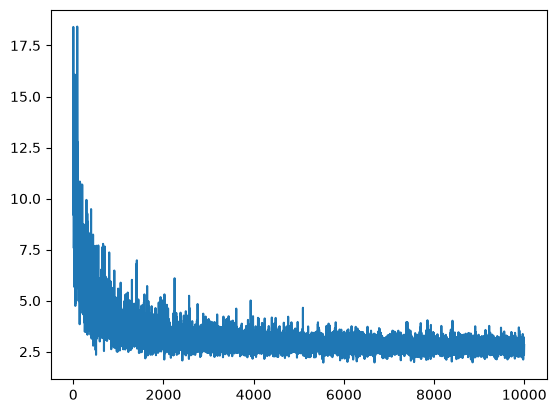

In [111]:
plt.plot(stepi, lossi)

In [10]:
# eval on training set
emb = C[xtr]
h = emb.view(-1,36) @ w1 + b1
logits = h @ w2 + b2
loss = F.cross_entropy(logits, ytr)
print(loss.item())

2.2833797931671143


In [ ]:
# eval on dev set
emb = C[xdev]
h = emb.view(-1,36) @ w1 + b1
logits = h @ w2 + b2
loss = F.cross_entropy(logits, ydev)
print(loss.item())

2.2677698135375977


In [11]:
# eval on test set
emb = C[xtest]
h = emb.view(-1,36) @ w1 + b1
logits = h @ w2 + b2
loss = F.cross_entropy(logits, ytest)
print(loss.item())

2.2874934673309326


model's loss on 3 data sets are similar and pretty high, try adjusting hyperparameters

In [15]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

NameError: name 'plt' is not defined

In [ ]:
# Sampling
for _ in range(10):
  out = []
  context = [0] * context_size
  while True:
    emb = C[torch.tensor([context])]
    h = torch.tanh(emb.view(1, -1) @ w1 + b1)
    logits = h @ w2 + b2
    probs = F.softmax(logits, dim=1)
    idx = torch.multinomial(probs, num_samples=1, generator=g).item()
    out.append(idx)
    context = context[1:] + [idx]
    if idx == 0:
      break

    print("".join(itos[i] for i in out))

e
ep
epw
epwy
epwyn
epwynn
epwynni
epwynnig
epwynnigo
epwynnigor
m
ma
mag
mago
magom
magomi
a
ah
ahz
ahzi
ahzim
ahzima
ahzimah
ahzimahi
ahzimahis
ahzimahish
ahzimahishy
ahzimahishya
ahzimahishyam
ahzimahishyami
ahzimahishyamic
ahzimahishyamicq
ahzimahishyamicqo
ahzimahishyamicqot
ahzimahishyamicqotf
ahzimahishyamicqotfm
ahzimahishyamicqotfma
ahzimahishyamicqotfmay
g
gr
gre
grer
m
mi
mie
mier
mierl
mierli
mierlia
mierlian
e
er
erm
erma
ermal
ermale
ermaley
ermaleya
ermaleyan
ermaleyann
a
an
any
anya
l
lo
lov
lovu
lovuo
lovuon
l
ly
lya
lyay
lyayl
lyayli
lyaylis
lyaylisz
lyaylisze
lyayliszee
lyayliszeei
lyayliszeeis
lyayliszeeiso
lyayliszeeisos
lyayliszeeisosh
lyayliszeeisoshe
lyayliszeeisoshen
lyayliszeeisosheno
lyayliszeeisoshenoe
t
th
tht
thte
thten
thtent
thtente


In [37]:
print(loss.item(), lossi[-1])
print([torch.isfinite(p).all().item() for p in parameters])

AcceleratorError: CUDA error: device-side assert triggered
Search for `cudaErrorAssert' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
The CUDA driver logged these messages, which may provide useful details:
Sticky error detected
Returning 710 (CUDA_ERROR_ASSERT) from cuMemcpyDtoHAsync_v2

